In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path


In [2]:
country_colors = {
    "Senegal": "cornflowerblue",
    "Guinea": "navajowhite",
    "Nigeria": "springgreen",
    "Cameroon": "mediumorchid",
    "Kenya": "lightcoral"
}

# Load summary files
files = list(Path("roh_hmm_2RL_by_country").glob("summary_*.csv"))
df = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)

df.head()

,sample_id,country,admin1_name,n_roh,FROH_2RL,FROH_2RL_HMM_raw
0,VBS84387-6020STDY14423812,Senegal,Kolda,7,0.014372,0.018418
1,VBS84393-6020STDY14423818,Senegal,Kolda,9,0.021693,0.024413
2,VBS84394-6020STDY14423819,Senegal,Kolda,10,0.022797,0.024127
3,VBS84409-6020STDY14423834,Senegal,Kolda,9,0.020448,0.028348
4,VBS84417-6020STDY14423842,Senegal,Kolda,8,0.021012,0.024869


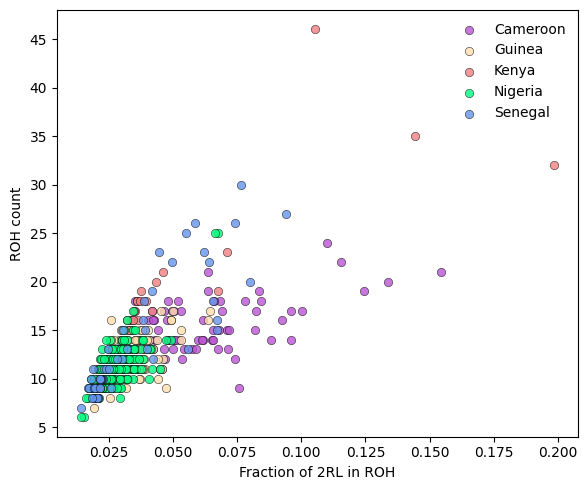

In [3]:
plt.figure(figsize=(6,5))

for country, d in df.groupby("country"):
    plt.scatter(
        d["FROH_2RL"],
        d["n_roh"],
        color=country_colors[country],
        label=country,
        alpha=0.8,
        edgecolor="black",
        linewidth=0.4
    )

plt.xlabel("Fraction of 2RL in ROH")
plt.ylabel("ROH count")
plt.legend(frameon=False)
plt.tight_layout()
plt.show()


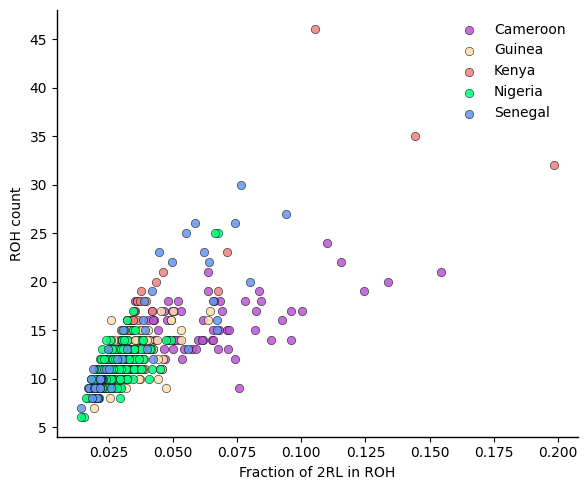

In [4]:


plt.figure(figsize=(6,5))

for country, d in df.groupby("country"):
    plt.scatter(
        d["FROH_2RL"],
        d["n_roh"],
        color=country_colors[country],
        label=country,
        alpha=0.85,
        edgecolor="black",
        linewidth=0.4
    )

ax = plt.gca()

# Remove grid
ax.grid(False)

# Remove top and right spines
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Keep left and bottom clean
ax.spines["left"].set_linewidth(1)
ax.spines["bottom"].set_linewidth(1)

plt.xlabel("Fraction of 2RL in ROH")
plt.ylabel("ROH count")
plt.legend(frameon=False)

plt.tight_layout()
plt.show()


/tmp/ipykernel_368447/2740097398.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


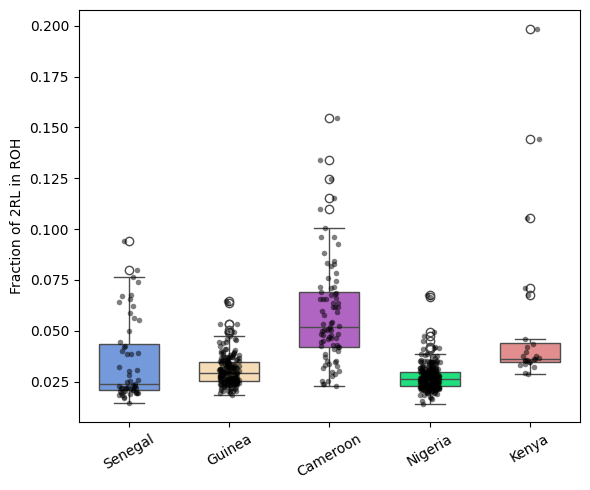

In [5]:
plt.figure(figsize=(6,5))

sns.boxplot(
    data=df,
    x="country",
    y="FROH_2RL",
    palette=country_colors,
    width=0.6
)

sns.stripplot(
    data=df,
    x="country",
    y="FROH_2RL",
    color="black",
    alpha=0.5,
    size=4
)

plt.ylabel("Fraction of 2RL in ROH")
plt.xlabel("")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


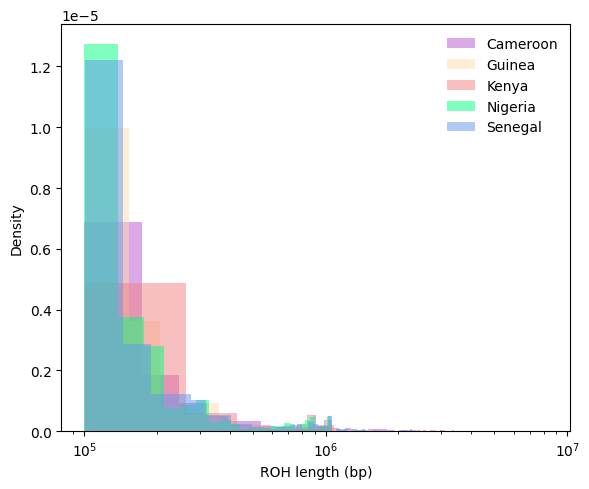

In [6]:
files = list(Path("roh_hmm_2RL_by_country").glob("segments_*.csv"))
seg = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)

plt.figure(figsize=(6,5))

for country, d in seg.groupby("country"):
    plt.hist(
        d["length"],
        bins=50,
        alpha=0.5,
        color=country_colors[country],
        label=country,
        density=True
    )

plt.xscale("log")
plt.xlabel("ROH length (bp)")
plt.ylabel("Density")
plt.legend(frameon=False)
plt.tight_layout()
plt.show()


In [7]:
files = list(Path("roh_hmm_2RL_by_country").glob("segments_*.csv"))
seg = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)

seg.head()


,start,stop,length,is_marginal,sample_id,country,admin1_name
0,404306,610961,206656,False,AK0123-C,Kenya,Kilifi
1,24028055,24188534,160480,False,AK0123-C,Kenya,Kilifi
2,24717683,24844879,127197,False,AK0123-C,Kenya,Kilifi
3,25304579,25479403,174825,False,AK0123-C,Kenya,Kilifi
4,25887671,25994033,106363,False,AK0123-C,Kenya,Kilifi


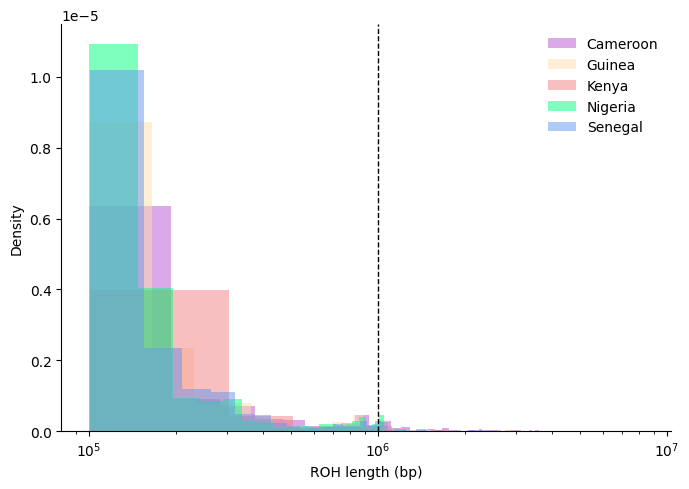

In [11]:
plt.figure(figsize=(7,5))

for country, d in seg.groupby("country"):
    plt.hist(
        d["length"],
        bins=40,
        density=True,
        alpha=0.5,
        color=country_colors[country],
        label=country
    )

ax = plt.gca()

# Log scale
ax.set_xscale("log")

# Remove grid and top/right spines
ax.grid(False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.axvline(1_000_000, color="black", linestyle="--", linewidth=1)

plt.xlabel("ROH length (bp)")
plt.ylabel("Density")
plt.legend(frameon=False)
plt.tight_layout()
plt.show()


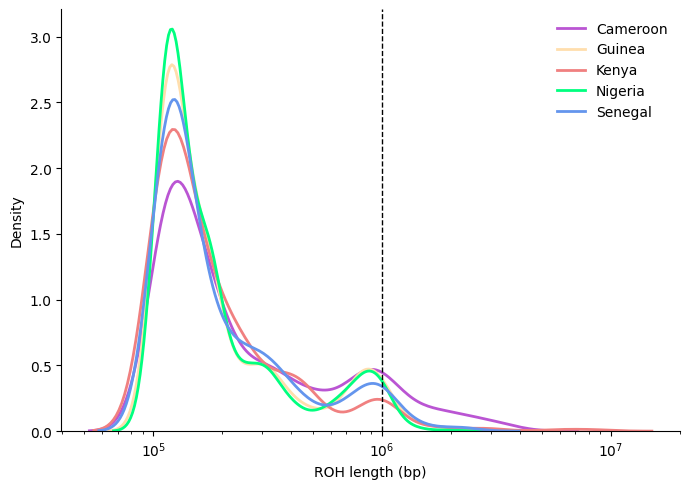

In [10]:
import seaborn as sns

plt.figure(figsize=(7,5))

for country, d in seg.groupby("country"):
    sns.kdeplot(
        data=d,
        x="length",
        log_scale=True,
        color=country_colors[country],
        linewidth=2,
        label=country
    )

ax = plt.gca()
ax.grid(False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.axvline(1_000_000, color="black", linestyle="--", linewidth=1)


plt.xlabel("ROH length (bp)")
plt.ylabel("Density")
plt.legend(frameon=False)
plt.tight_layout()
plt.show()
